# Predicción de Churn en un Banco

## Contexto
La entidad financiera tuvo una reducción del **15%** de clientes activos en el último trimestre. Para retenerlos diseñó un programa de beneficios (eliminación de cuota de manejo, mejores tasas, retiros ilimitados) y necesita **identificar qué clientes son más propensos a retirarse** para **priorizar** a quién ofrecerlos.

**Objetivo analítico:** Construir un modelo que estime la probabilidad de churn de cada cliente y usarlo para ordenar la campaña de retención.

## Metodología (CRISP-DM)
1. Entendimiento del negocio: problema del banco y objetivo del modelo (ver Contexto)
2. Entendimiento de los datos: calidad, variable objetivo y análisis exploratorio (EDA)
3. Preparación de datos: codificación, escalado, manejo del desbalance y partición train/test
4. Modelado: Optimización (descenso de gradiente), SVM, Redes Neuronales y Ensambles (Bagging, Random Forest, AdaBoost, Gradient Boosting, XGBoost)
5. Evaluación: comparación y selección del modelo, umbral de decisión e impacto de negocio con Simulación Montecarlo
6. Despliegue: priorización de clientes para la campaña de retención y recomendaciones de monitoreo

## 0. Configuración del notebook

In [1]:
%load_ext autoreload
%autoreload 2

Librerías y configuración de estilo y visualización.

In [2]:
import sys
from pathlib import Path

In [3]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [4]:
import pandas as pd
from IPython.display import display

from src import config as cfg
from src import viz
from src.data_understanding import eda, loading, quality

In [5]:
viz.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

## 2. Entendimiento de los datos
### 2.1 Carga y diccionario de variables

In [6]:
df_raw = loading.load_raw()
print(f"Dimensiones: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
df_raw.head()

Dimensiones: 10,127 filas x 21 columnas


,clientnum,attrition_flag,customer_age,gender,dependent_count,education_level,marital_status,income_category,card_category,months_on_book,total_relationship_count,months_inactive_12_mon,contacts_count_12_mon,credit_limit,total_revolving_bal,avg_open_to_buy,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,"12,691.000",777,"11,914.000",1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,"8,256.000",864,"7,392.000",1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,"3,418.000",0,"3,418.000",2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,"3,313.000",2517,796.000,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,"4,716.000",0,"4,716.000",2.175,816,28,2.500,0.000


In [3]:
quality.data_dictionary(df_raw)

,descripcion,tipo,nulos,unicos,ejemplo
variable,,,,,
clientnum,Identificador único del cliente,int64,0,10127,768805383
attrition_flag,Variable objetivo: el cliente se fue a otro ba...,str,0,2,Existing Customer
customer_age,Edad del cliente,int64,0,45,45
gender,Sexo del cliente,str,0,2,M
dependent_count,Número de personas económicamente dependientes,int64,0,6,3
education_level,Nivel educativo,str,0,7,High School
marital_status,Estado civil,str,0,4,Married
income_category,Categoría de ingresos,str,0,6,$60K - $80K
card_category,Categoría de tarjeta,str,0,4,Blue


### 2.2 Calidad de los datos

In [7]:
quality.quality_report(df_raw).to_frame()

,valor
filas,10127
columnas,21
celdas nulas,0
filas duplicadas,0
clientnum único,True
celdas 'Unknown',3380
filas con algún 'Unknown',3046
% filas con 'Unknown',30.080


In [8]:
df = loading.load_data()

In [9]:
quality.unknown_summary(df)

,n_unknown,% registros,churn % (Unknown),churn % (resto)
variable,,,,
education_level,1519,15.000,16.850,15.930
marital_status,749,7.400,17.220,15.970
income_category,1112,10.980,16.820,15.970


### 2.3 Variable objetivo

,n,%
clase,,
Existing (0),8500,83.930
Attrited (1),1627,16.070


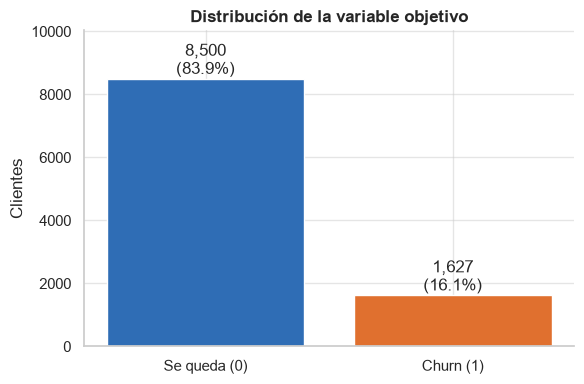

In [10]:
display(quality.target_distribution(df))
fig = eda.plot_target(df)
viz.save_fig(fig, "01_target_distribution")

### 2.4 Estadísticas descriptivas

In [11]:
df[cfg.NUMERIC_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
customer_age,"10,127.000",46.326,8.017,26.000,41.000,46.000,52.000,73.000
dependent_count,"10,127.000",2.346,1.299,0.000,1.000,2.000,3.000,5.000
months_on_book,"10,127.000",35.928,7.986,13.000,31.000,36.000,40.000,56.000
total_relationship_count,"10,127.000",3.813,1.554,1.000,3.000,4.000,5.000,6.000
months_inactive_12_mon,"10,127.000",2.341,1.011,0.000,2.000,2.000,3.000,6.000
contacts_count_12_mon,"10,127.000",2.455,1.106,0.000,2.000,2.000,3.000,6.000
credit_limit,"10,127.000","8,631.954","9,088.777","1,438.300","2,555.000","4,549.000","11,067.500","34,516.000"
total_revolving_bal,"10,127.000","1,162.814",814.987,0.000,359.000,"1,276.000","1,784.000","2,517.000"
avg_open_to_buy,"10,127.000","7,469.140","9,090.685",3.000,"1,324.500","3,474.000","9,859.000","34,516.000"
total_amt_chng_q4_q1,"10,127.000",0.760,0.219,0.000,0.631,0.736,0.859,3.397


In [12]:
for col in cfg.CATEGORICAL_COLS:
    display(df[col].value_counts().to_frame("n").assign(**{"%": lambda t: (100 * t["n"] / t["n"].sum()).round(2)}).T)

gender,F,M
n,"5,358.000","4,769.000"
%,52.910,47.090


education_level,Graduate,High School,Unknown,Uneducated,College,Post-Graduate,Doctorate
n,"3,128.000","2,013.000","1,519.000","1,487.000","1,013.000",516.000,451.000
%,30.890,19.880,15.000,14.680,10.000,5.100,4.450


marital_status,Married,Single,Unknown,Divorced
n,"4,687.000","3,943.000",749.000,748.000
%,46.280,38.940,7.400,7.390


income_category,Less than $40K,$40K - $60K,$80K - $120K,$60K - $80K,Unknown,$120K +
n,"3,561.000","1,790.000","1,535.000","1,402.000","1,112.000",727.000
%,35.160,17.680,15.160,13.840,10.980,7.180


card_category,Blue,Silver,Gold,Platinum
n,"9,436.000",555.000,116.000,20.000
%,93.180,5.480,1.150,0.200


### Conclusiones: entendimiento de los datos

- **Base limpia a nivel técnico:** 10.127 clientes, 21 variables, sin valores nulos ni filas duplicadas; `clientnum` es único y se usa solo como índice (no es predictor).
- **Datos faltantes:** `education_level` (15,0%), `income_category` (11,0%) y `marital_status` (7,4%) usan la categoría **"Unknown"**. No son nulos explícitos, pero sí información faltante. La tasa de churn en esos registros es similar a la del resto, por lo que se trabajarán como **categoría propia** en lugar de eliminarlos (se perdería cerca del 30% de la base).
- **Desbalance de clases:** solo el **16,1%** de los clientes hizo churn (1.627 vs 8.500). Un modelo que prediga "nadie se va" tendría 84% de accuracy y sería inútil, así que la **accuracy no sirve como métrica principal**: usaremos Recall, Precision, F1, ROC-AUC y sobre todo PR-AUC de la clase churn, además de técnicas para el desbalance (pesos de clase, SMOTE, ajuste de umbral).
- **`card_category` muy concentrada:** 93% de los clientes tiene tarjeta Blue; Gold y Platinum tienen pocos casos (116 y 20), lo que limita su poder explicativo.
- Las escalas de las variables numéricas son muy distintas (p. ej. `credit_limit` llega a 34.516 y `avg_utilization_ratio` está entre 0 y 1), por lo que **SVM, redes neuronales y la logística por gradiente necesitarán escalado**.